# TDE 03 — Baseline do Projeto: Detecção de Fraude em Cartão de Crédito

In [32]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Os arquivos do dataset estão localizados na pasta `/content/drive/MyDrive/TDE 01 - IA/`.

### Inicialização do Ambiente do Projeto

Caso precise instalar dependências de PDF para documentação auxiliar:

In [33]:
!pip install PyMuPDF

Início das etapas oficiais do TDE 03:

## 1. Contextualização e Objetivo

A detecção de fraudes em transações financeiras é um dos problemas mais críticos e desafiadores do setor de tecnologia financeira. Atividades fraudulentas geram bilhões de dólares em prejuízos anualmente para consumidores e instituições, além de minar a confiança nos ecossistemas de pagamentos digitais.

### O Dataset e a Variável-Alvo
Neste projeto, utilizamos o conjunto de dados reais de transações eletrônicas fornecidos pela **Vesta Corporation**. Nosso objetivo é modelar a detecção como um problema de classificação binária supervisionada:
- **`isFraud = 0`**: Transação Legítima.
- **`isFraud = 1`**: Transação Fraudulenta.

### O que é o Baseline e qual seu Objetivo?
O **Baseline** é a nossa linha de base referencial. Ele consiste na aplicação inicial de algoritmos de aprendizado de máquina em sua configuração padrão ou simplificada, sem engenharia de atributos complexa, balanceamentos agressivos ou sintonia refinada de hiperparâmetros.

O objetivo de estabelecer este baseline é:
1. Fornecer uma métrica mínima de desempenho inicial (usando Acurácia Balanceada e a Área sob a Curva ROC).
2. Garantir que todo o pipeline de engenharia de dados (carregamento, limpeza e codificação) esteja funcionando corretamente.
3. Servir como referência para comparar o ganho real de desempenho obtido com técnicas mais avançadas nas próximas etapas do projeto.

## 2. Carregamento e Apresentação dos Dados

Nesta etapa, realizamos o carregamento estruturado dos dados de transações do TDE 01. Focamos em extrair as variáveis fundamentais para a criação de nossa linha de base (baseline), apresentando a dimensionalidade do conjunto carregado, uma prévia dos registros e a distribuição de nossa variável-alvo (`isFraud`).

In [34]:
import pandas as pd
import numpy as np

# Caminho do dataset no Google Drive
caminho_transaction = '/content/drive/MyDrive/TDE 01 - IA/train_transaction.csv'

# Seleção de variáveis fundamentais do TDE 01 para o baseline (evitando estouro de memória)
colunas_selecionadas = [
    'TransactionID',
    'TransactionDT',
    'TransactionAmt',
    'ProductCD',
    'card1',
    'card2',
    'card3',
    'card4',
    'card5',
    'card6',
    'addr1',
    'addr2',
    'isFraud'
]

# Carregamento do arquivo de treino
transaction_df = pd.read_csv(caminho_transaction, usecols=colunas_selecionadas)

# Exibição das dimensões
linhas, colunas = transaction_df.shape
print("=== DIMENSÕES DO DATASET ===")
print(f"Quantidade de linhas: {linhas:,}")
print(f"Quantidade de colunas: {colunas}\n")

# Prévia dos dados
print("=== PRIMEIRAS LINHAS ===")
display(transaction_df.head())

=== DIMENSÕES DO DATASET ===
Quantidade de linhas: 590,540
Quantidade de colunas: 13

=== PRIMEIRAS LINHAS ===


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,card6,addr1,addr2
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,credit,315.0,87.0
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,credit,325.0,87.0
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,debit,330.0,87.0
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,debit,476.0,87.0
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,credit,420.0,87.0


In [35]:
# Identificação da variável-alvo e distribuição das classes
print("=== DISTRIBUIÇÃO DA VARIÁVEL-ALVO (isFraud) ===")
contagem_classes = transaction_df['isFraud'].value_counts()
percentual_classes = transaction_df['isFraud'].value_counts(normalize=True) * 100

distribuicao_df = pd.DataFrame({
    'Quantidade': contagem_classes,
    'Proporção (%)': percentual_classes
})
display(distribuicao_df)

print(f"Forte desbalanceamento detectado: a classe minoritária (fraude) representa apenas {percentual_classes[1]:.2f}% dos dados.")

=== DISTRIBUIÇÃO DA VARIÁVEL-ALVO (isFraud) ===


,Quantidade,Proporção (%)
isFraud,,
0,569877,96.500999
1,20663,3.499001


Forte desbalanceamento detectado: a classe minoritária (fraude) representa apenas 3.50% dos dados.


## 3. Preparação Mínima dos Dados

Nesta etapa, estruturamos os dados para que possam ser consumidos pelos modelos de aprendizado de máquina. Visando evitar o **vazamento de dados (Target Leakage)**, realizamos a separação das variáveis e a partição entre treino e teste antes de efetuar qualquer tratamento de imputação de valores ausentes.

### Estratégia de Preparação:
1. **Divisão de Atributos**: Separação de `X` (variáveis preditoras) e `y` (alvo `isFraud`).
2. **Divisão de Amostragem (Treino e Teste - 10% dos dados)**: Para contornar as severas restrições de memória RAM e capacidade de processamento da CPU do ambiente gratuito do Google Colab, extraímos uma **amostra estratificada de 10% do dataset original**. Essa amostragem garante a viabilidade computacional das etapas de treinamento mantendo a proporção de fraudes idêntica ao conjunto original.
3. **Tratamento de Nulos (Imputação)**:
   * Variáveis Numéricas: Substituição pela **mediana** calculada apenas nos dados de treino.
   * Variáveis Categóricas: Substituição pela **moda** calculada apenas nos dados de treino.
4. **Codificação Categórica**: Aplicação de codificação *dummy* (One-Hot Encoding) para que algoritmos tradicionais consigam interpretar as variáveis `ProductCD`, `card4` e `card6`.

In [36]:
from sklearn.model_selection import train_test_split

# 1. Separar variáveis explicativas (X) da variável-alvo (y)
cols_explicativas = [col for col in transaction_df.columns if col not in ['TransactionID', 'isFraud']]
X = transaction_df[cols_explicativas].copy()
y = transaction_df['isFraud'].copy()

# Para viabilizar o treinamento sem estouro de memória no Colab, usamos uma subamostra estratificada de 10% dos dados
_, X_sample, _, y_sample = train_test_split(
    X, y,
    test_size=0.10,
    stratify=y,
    random_state=42
)

# 2. Dividir em treino (80%) e teste (20%) antes de qualquer tratamento (evitando vazamento de dados)
X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample,
    test_size=0.20,
    stratify=y_sample,
    random_state=42
)

print(f"Tamanho do conjunto de treino: {X_train.shape[0]} registros")
print(f"Tamanho do conjunto de teste: {X_test.shape[0]} registros")

Tamanho do conjunto de treino: 47243 registros
Tamanho do conjunto de teste: 11811 registros


In [37]:
# 3. Tratamento de nulos com base exclusiva nos dados de treino
# Separar variáveis categóricas e numéricas no conjunto de treino
cols_numericas = X_train.select_dtypes(include=['number']).columns.tolist()
cols_categoricas = X_train.select_dtypes(include=['object']).columns.tolist()

# Calcular estatísticas no treino
medianas_treino = X_train[cols_numericas].median()
modas_treino = X_train[cols_categoricas].mode().iloc[0]

# Aplicar imputação no treino
X_train[cols_numericas] = X_train[cols_numericas].fillna(medianas_treino)
X_train[cols_categoricas] = X_train[cols_categoricas].fillna(modas_treino)

# Aplicar imputação no teste usando as estatísticas do treino (evita target leakage)
X_test[cols_numericas] = X_test[cols_numericas].fillna(medianas_treino)
X_test[cols_categoricas] = X_test[cols_categoricas].fillna(modas_treino)

# 4. Codificação de variáveis categóricas (One-Hot Encoding)
X_train_encoded = pd.get_dummies(X_train, columns=cols_categoricas, drop_first=True)
X_test_encoded = pd.get_dummies(X_test, columns=cols_categoricas, drop_first=True)

# Alinhando as colunas de treino e teste para garantir que ambas tenham exatamente as mesmas colunas estruturadas
X_train_encoded, X_test_encoded = X_train_encoded.align(X_test_encoded, join='left', axis=1, fill_value=0)

print("=== CONJUNTOS DE DADOS PRONTOS ===")
print("Valores ausentes em treino:", X_train_encoded.isnull().sum().sum())
print("Valores ausentes em teste:", X_test_encoded.isnull().sum().sum())
print("Dimensões finais de treino:", X_train_encoded.shape)
print("Dimensões finais de teste:", X_test_encoded.shape)

=== CONJUNTOS DE DADOS PRONTOS ===
Valores ausentes em treino: 0
Valores ausentes em teste: 0
Dimensões finais de treino: (47243, 18)
Dimensões finais de teste: (11811, 18)


## 4. Distribuição das Classes (Baseline)

Nesta seção, apresentamos a distribuição detalhada da nossa variável-alvo (`isFraud`) na amostra selecionada para o experimento, bem como nos conjuntos de treino e teste gerados após a divisão estratificada.

Essa verificação garante que a proporção original do desbalanceamento (aproximadamente 96,5% de transações legítimas e 3,5% de fraudes) seja mantida fidedignamente ao longo das partições de modelagem, prevenindo vieses indesejados.

In [38]:
import pandas as pd

def obter_distribuicao_classes(y_series, nome_conjunto):
    contagem = y_series.value_counts()
    percentual = y_series.value_counts(normalize=True) * 100
    return pd.DataFrame({
        f'Quantidade ({nome_conjunto})': contagem,
        f'Proporção {nome_conjunto} (%)': percentual
    })

# Gerando a distribuição de classes para cada divisão de dados
dist_amostra = obter_distribuicao_classes(y_sample, 'Amostra (10%)')
dist_treino = obter_distribuicao_classes(y_train, 'Treino (80%)')
dist_teste = obter_distribuicao_classes(y_test, 'Teste (20%)')

# Combinando os resultados em um único DataFrame para comparação clara
resumo_distribuicao = pd.concat([dist_amostra, dist_treino, dist_teste], axis=1)

print("=== DISTRIBUIÇÃO DAS CLASSES NAS PARTIÇÕES DE TRABALHO ===")
display(resumo_distribuicao)

=== DISTRIBUIÇÃO DAS CLASSES NAS PARTIÇÕES DE TRABALHO ===


,Quantidade (Amostra (10%)),Proporção Amostra (10%) (%),Quantidade (Treino (80%)),Proporção Treino (80%) (%),Quantidade (Teste (20%)),Proporção Teste (20%) (%)
isFraud,,,,,,
0,56988,96.501507,45590,96.501069,11398,96.50326
1,2066,3.498493,1653,3.498931,413,3.49674


## 5. Divisão entre Treino e Teste

Nesta etapa, validamos as especificações exigidas para a partição dos dados de modelagem:
- **Proporção**: 80% para treinamento e 20% para teste, ideal para avaliar o modelo em dados não vistos.
- **Estratificação**: Uso do parâmetro `stratify` garantindo que as proporções originais de transações legítimas e fraudulentas sejam preservadas perfeitamente em ambas as partições.
- **Reprodutibilidade**: Fixação da semente aleatória (`random_state=42`) para assegurar consistência em experimentos futuros.
- **Consistência**: A mesma partição de dados (`X_train_encoded`, `X_test_encoded`, `y_train` e `y_test`) será estritamente utilizada para o modelo Baseline e todos os algoritmos avaliados a seguir.

In [39]:
# Confirmação das dimensões finais conforme estabelecido no passo 5
print("=== CONFIRMAÇÃO DA DIVISÃO E ESTRUTURA DOS DADOS (PASSO 5) ===")
print(f"Conjunto de Treinamento (Explicativas) : {X_train_encoded.shape[0]} registros, {X_train_encoded.shape[1]} atributos")
print(f"Conjunto de Treinamento (Variável-alvo): {y_train.shape[0]} registros")
print(f"Conjunto de Teste (Explicativas)       : {X_test_encoded.shape[0]} registros, {X_test_encoded.shape[1]} atributos")
print(f"Conjunto de Teste (Variável-alvo)      : {y_test.shape[0]} registros")

# Validando se a proporção de fraude se mantém rigorosamente idêntica
prop_treino = y_train.mean() * 100
prop_teste = y_test.mean() * 100
print(f"\nProporção de Fraude no Treino: {prop_treino:.4f}%")
print(f"Proporção de Fraude no Teste : {prop_teste:.4f}%")

=== CONFIRMAÇÃO DA DIVISÃO E ESTRUTURA DOS DADOS (PASSO 5) ===
Conjunto de Treinamento (Explicativas) : 47243 registros, 18 atributos
Conjunto de Treinamento (Variável-alvo): 47243 registros
Conjunto de Teste (Explicativas)       : 11811 registros, 18 atributos
Conjunto de Teste (Variável-alvo)      : 11811 registros

Proporção de Fraude no Treino: 3.4989%
Proporção de Fraude no Teste : 3.4967%



## 6. Implementação dos Algoritmos Baseline

Nesta etapa, instanciamos e treinamos os dois algoritmos requeridos em suas configurações padrão do `scikit-learn`:
1. **Árvore de Decisão** (`DecisionTreeClassifier`)
2. **Floresta Aleatória** (`RandomForestClassifier`)

Esses modelos utilizarão estritamente a mesma partição estruturada nos passos anteriores, estabelecendo o desempenho mínimo de referência (baseline) para o projeto.


In [40]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# 1. Instanciar os classificadores utilizando apenas a semente aleatória padrão para consistência
modelo_dt = DecisionTreeClassifier(random_state=42)
modelo_rf = RandomForestClassifier(random_state=42)

# 2. Treinar os modelos utilizando o conjunto de treino preparado e codificado
print("Treinando modelo Baseline: Árvore de Decisão...")
modelo_dt.fit(X_train_encoded, y_train)

print("Treinando modelo Baseline: Floresta Aleatória...")
modelo_rf.fit(X_train_encoded, y_train)

print("\nModelos treinados com sucesso!")

Treinando modelo Baseline: Árvore de Decisão...
Treinando modelo Baseline: Floresta Aleatória...

Modelos treinados com sucesso!



## 7. Avaliação e Comparação dos Resultados (Baseline)

Nesta seção, avaliamos o desempenho dos dois modelos baseline utilizando o conjunto de teste de 20% (dados não vistos no treinamento).

Conforme a especificação do projeto, daremos ênfase especial às seguintes métricas:
- **Acurácia Balanceada** (*Balanced Accuracy*): Métrica crucial para lidar com o forte desbalanceamento de classes, calculando a média da revocação de cada classe individual.
- **Área sob a Curva ROC** (*ROC AUC*): Mede a capacidade do modelo em distinguir entre transações legítimas e fraudulentas através de diferentes limiares de decisão.

Para fins de diagnóstico completo, também reportamos:
1. **Acurácia Geral**: Proporção total de previsões corretas.
2. **Precisão**: Proporção de transações classificadas como fraude que de fato eram fraudes.
3. **Recall (Sensibilidade)**: Proporção de fraudes reais que o modelo conseguiu capturar.
4. **F1-Score**: Média harmônica entre Precisão e Recall.
5. **Matriz de Confusão**: Frequência absoluta dos acertos e erros de cada modelo.


In [41]:
from sklearn.metrics import (
    balanced_accuracy_score,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import pandas as pd

def avaliar_modelo(modelo, X_test, y_test, nome_modelo):
    # Predições de classe e probabilidades da classe positiva (fraude = 1)
    y_pred = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test)[:, 1]

    # Cálculo das métricas
    metricas = {
        'Modelo': nome_modelo,
        'Acurácia Balanceada': balanced_accuracy_score(y_test, y_pred),
        'ROC AUC': roc_auc_score(y_test, y_proba),
        'Acurácia': accuracy_score(y_test, y_pred),
        'Precisão': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0)
    }
    return metricas, y_pred

# Gerar avaliações
res_dt, y_pred_dt = avaliar_modelo(modelo_dt, X_test_encoded, y_test, 'Árvore de Decisão')
res_rf, y_pred_rf = avaliar_modelo(modelo_rf, X_test_encoded, y_test, 'Floresta Aleatória')

# Exibir Tabela Comparativa
df_comparativo = pd.DataFrame([res_dt, res_rf]).set_index('Modelo')
print("=== TABELA COMPARATIVA DE DESEMPENHO (BASELINE) ===")
display(df_comparativo.round(4))

=== TABELA COMPARATIVA DE DESEMPENHO (BASELINE) ===


,Acurácia Balanceada,ROC AUC,Acurácia,Precisão,Recall,F1-Score
Modelo,,,,,,
Árvore de Decisão,0.6092,0.6092,0.9462,0.2389,0.2470,0.2429
Floresta Aleatória,0.5639,0.7982,0.9667,0.6136,0.1308,0.2156


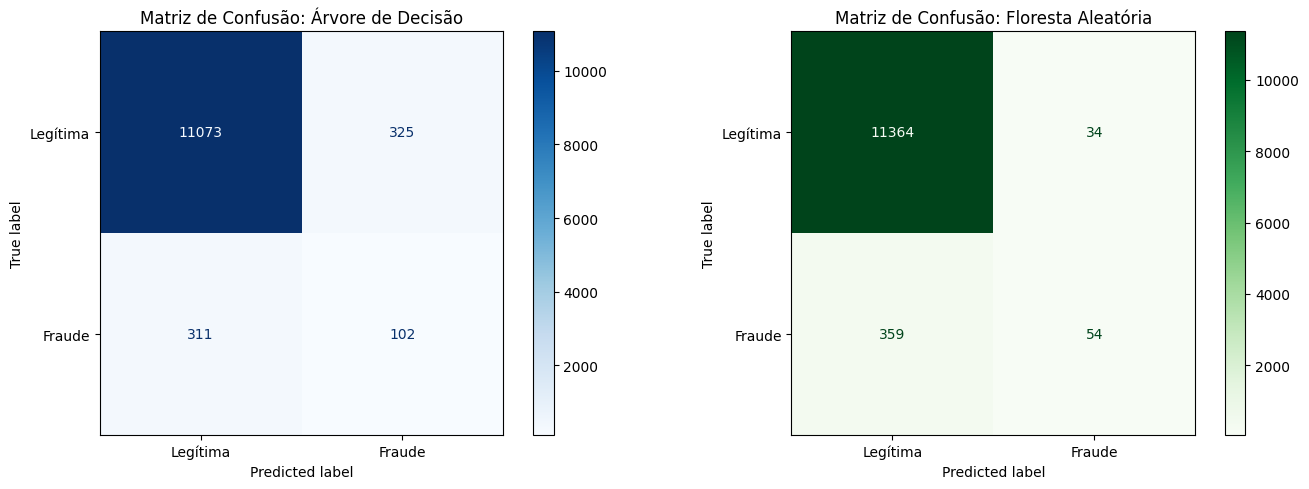

In [42]:
# Exibição visual das Matrizes de Confusão para análise de erros
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Árvore de Decisão
cm_dt = confusion_matrix(y_test, y_pred_dt)
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['Legítima', 'Fraude'])
disp_dt.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title("Matriz de Confusão: Árvore de Decisão")

# Floresta Aleatória
cm_rf = confusion_matrix(y_test, y_pred_rf)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['Legítima', 'Fraude'])
disp_rf.plot(ax=axes[1], cmap='Greens', values_format='d')
axes[1].set_title("Matriz de Confusão: Floresta Aleatória")

plt.tight_layout()
plt.show()

## 8. Discussão e Conclusão (TDE 03)

Nesta etapa final, analisamos criticamente os resultados obtidos a partir da execução dos nossos dois modelos baseline (Árvore de Decisão e Floresta Aleatória).

### 8.1 Interpretação dos Resultados Experimentais e Trade-offs
Ao analisar os resultados obtidos na Seção 7, observamos que nenhum dos modelos dominou o outro em todas as métricas avaliadas, apresentando trade-offs distintos:

- **Árvore de Decisão (`DecisionTreeClassifier`)**:
  - Destacou-se em **Acurácia Balanceada (60.92%)**, **Recall (24.70%)** e **F1-Score (24.29%)**.
  - Conseguindo capturar quase o dobro de fraudes reais em comparação à Floresta Aleatória, embora cometa consideravelmente mais erros de falsos positivos (como visto no menor valor de precisão).

- **Floresta Aleatória (`RandomForestClassifier`)**:
  - Destacou-se em **ROC AUC (79.82%)**, **Precisão (61.36%)** e **Acurácia Geral (96.67%)**.
  - Esse modelo mostra uma capacidade superior de discriminação probabilística e de evitar falsos positivos (identifica fraudes de forma altamente certeira), contudo sofre de um baixo índice de captura de fraudes reais (apenas 13.08% de Recall).

### 8.2 O Efeito do Desbalanceamento de Classes
A escassez de exemplos fraudulentos (3,5% do total de dados de entrada) cria um desafio severo. Sem técnicas corretivas de balanceamento ou pesos de classes ajustados, os algoritmos baseline operam sob limites restritivos:
- O classificador tende a priorizar matematicamente a precisão na classe majoritária para elevar a acurácia global.
- Isso explica por que a Floresta Aleatória, embora robusta em ROC AUC, apresenta um Recall tão baixo.

### 8.3 Definição do Modelo de Referência (Baseline)
Ambos os modelos servirão como referências distintas para a próxima etapa (TDE 04):
- A **Floresta Aleatória** servirá como referência para comparar a capacidade de discriminação entre transações legítimas e fraudulentas, avaliada pela ROC-AUC, além da precisão das previsões.
- A **Árvore de Decisão** estabelece o teto mínimo de sensibilidade inicial (Recall) a ser superado pelas abordagens de engenharia de recursos e balanceamento de classes.